# 03 — Modelling, Validation & Out-of-Time Testing
**NeoStats DS Hackathon — Loan Application Refusal Prediction**

| Step | What we do | Uses which data |
|---|---|---|
| 1 | Load the model table and the four splits | — |
| 2 | Build preprocessing pipelines (imputation + encoding) | **fitted on train only** |
| 3 | Baseline: Logistic Regression (class-weighted) | train → scored on validation |
| 4 | Stronger model: LightGBM (weighted & unweighted, light tuning) | train → validation |
| 5 | Leakage / reliance check (ablation) | train → validation |
| 6 | Compare all models on validation, choose model + threshold | validation |
| 7 | Score **test once**, then **OOT once** | test, OOT |
| 8 | Drift (PSI), KS/Gini, lift table, calibration | test, OOT |
| 9 | Risk bands (Low / Medium / High) | cut-offs from validation |
| 10 | Feature importance, save model + dashboard files | — |

**Golden rule:** train = learn, validation = choose, test & OOT = report. Test and OOT are never used to change anything.

In [1]:
import time, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import joblib
import lightgbm as lgb
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
                             accuracy_score, confusion_matrix, roc_curve, precision_recall_curve, brier_score_loss)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
SEED = 42
np.random.seed(SEED)
print("lightgbm", lgb.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

ON_KAGGLE = Path("/kaggle/input").exists()
IN_DIRS = [Path("/kaggle/input"), Path("/kaggle/working")] if ON_KAGGLE else [Path("../outputs"), Path("outputs")]
OUT_DIR = Path("/kaggle/working") if ON_KAGGLE else Path("../outputs")
MODEL_DIR = Path("/kaggle/working") if ON_KAGGLE else Path("../models")
FIG_DIR = OUT_DIR / "figures"
for d in (OUT_DIR, MODEL_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

def find(name):
    for d in IN_DIRS:
        if d.exists():
            hits = sorted(d.rglob(name))
            if hits:
                return hits[0]
    raise FileNotFoundError(f"{name} not found. On Kaggle: Add Input -> Your Work -> Notebooks -> notebook 01.")

df = pd.read_parquet(find("model_table.parquet"))
groups = pd.read_csv(find("feature_groups.csv"))
FEATURES = groups["feature"].tolist()
print("Rows:", len(df), "| model features:", len(FEATURES), "| CODE_GENDER in features:", "CODE_GENDER" in FEATURES)

BLUE, ORANGE, AQUA, GREY, INK2 = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#52514e"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d5d0",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#ebeae6", "axes.axisbelow": True, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "font.size": 10})

lightgbm 4.7.0 | scikit-learn 1.9.1 | pandas 3.0.5


Rows: 1327459 | model features: 52 | CODE_GENDER in features: False


## 1. Feature types and the four splits
* **Categorical** columns: missing values are filled with the label `"Missing"` — a fixed rule, nothing is learned from data, so it is safe to do before splitting.
* **Numeric** columns keep their `NaN`; their imputation (median) is *learned*, so it happens inside the pipeline on train only.

In [2]:
CAT = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(df[c])]
NUM = [c for c in FEATURES if c not in CAT]
for c in CAT:
    df[c] = df[c].astype("object").where(df[c].notna(), "Missing").astype(str)
print(f"{len(NUM)} numeric, {len(CAT)} categorical features")

split = {s: df.index[df["SPLIT"] == s] for s in ["train", "validation", "test", "oot"]}
X = {s: df.loc[i, FEATURES] for s, i in split.items()}
y = {s: df.loc[i, "REFUSED"].astype(int).values for s, i in split.items()}
summary = pd.DataFrame({s: {"rows": len(y[s]), "refusals": int(y[s].sum()), "refusal_rate": round(y[s].mean(), 4)} for s in y}).T
summary

27 numeric, 25 categorical features


,rows,refusals,refusal_rate
train,714467.0,123460.0,0.1728
validation,153100.0,26456.0,0.1728
test,153101.0,26456.0,0.1728
oot,306791.0,114306.0,0.3726


## 2. Metric helpers
* **ROC-AUC** — probability that a random refused application gets a higher score than a random approved one (0.5 = coin flip, 1.0 = perfect). Threshold-free *ranking* quality.
* **PR-AUC** (average precision) — area under the precision–recall curve; focuses on the refused (minority) class, so it is our **main selection metric**. Baseline = the refusal rate.
* **Precision** — of applications we flag as "will be refused", how many really are.
* **Recall** — of all real refusals, how many we flag.
* **F1** — harmonic mean of precision and recall.
* **Gini** = 2·AUC − 1 and **KS** = max gap between the score distributions of refused vs approved — standard credit-risk metrics.
* **Accuracy** is shown only to make the point that it is misleading: "always approve" scores 82.7% accuracy on validation.

In [3]:
def ks_stat(y_true, p):
    fpr, tpr, _ = roc_curve(y_true, p)
    return float(np.max(tpr - fpr))

def evaluate(y_true, p, thr, model, split_name):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    auc = roc_auc_score(y_true, p)
    return {"model": model, "split": split_name, "threshold": round(thr, 4),
            "roc_auc": auc, "pr_auc": average_precision_score(y_true, p), "gini": 2 * auc - 1,
            "ks": ks_stat(y_true, p), "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred), "f1": f1_score(y_true, pred), "accuracy": accuracy_score(y_true, pred),
            "tp": int(tp), "fp": int(fp), "tn": int(tn), "fn": int(fn),
            "actual_refusal_rate": float(np.mean(y_true)), "predicted_refusal_rate": float(pred.mean())}

def best_f1_threshold(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    i = int(np.nanargmax(f1[:-1]))
    return float(thr[i])

print("Validation accuracy of 'always approve':", round(1 - y["validation"].mean(), 4))

Validation accuracy of 'always approve': 0.8272


## 3. Preprocessing pipelines (fitted on train only)
| Model | Numeric | Categorical | Why |
|---|---|---|---|
| Logistic Regression | median imputation + missing-indicator → quantile transform to a normal shape | one-hot encoding (rare levels < 0.1% grouped) | LR needs numbers on comparable scales and cannot handle `NaN`; the quantile transform stops extreme incomes (up to 117M) from dominating |
| LightGBM | left as is — LightGBM handles `NaN` natively | ordinal codes, declared as categorical | trees do not need scaling; native categorical handling is faster and more accurate than one-hot |

Both are wrapped in an sklearn `Pipeline`, so `fit` on train learns medians/quantiles/categories from **train only**, and the same fitted steps are re-used unchanged for validation, test, OOT and new applications.

In [4]:
def make_lr_pre():
    num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                    ("scale", QuantileTransformer(n_quantiles=200, output_distribution="normal", subsample=200_000, random_state=SEED))])
    cat = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.001)
    return ColumnTransformer([("num", num, NUM), ("cat", cat, CAT)])

def make_tree_pre(num_cols=NUM, cat_cols=CAT):
    cat = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=np.int32)
    return ColumnTransformer([("num", "passthrough", num_cols), ("cat", cat, cat_cols)])

results, val_scores, models = [], {}, {}

## 4. Baseline — Logistic Regression
**How it works:** it gives every feature a weight, adds them up into a score, and squashes the score into a probability between 0 and 1. Positive weight → pushes towards "refused".
**Why as baseline:** simple, fast, fully explainable (each weight can be read), and tells us how much a complex model really adds.
**Imbalance:** `class_weight="balanced"` makes each refused application count ~2.9× more during training, so the model does not just learn "approve everything".

In [5]:
t0 = time.time()
lr_pipe = Pipeline([("pre", make_lr_pre()),
                    ("model", LogisticRegression(class_weight="balanced", C=1.0, max_iter=1000, random_state=SEED))])
lr_pipe.fit(X["train"], y["train"])
p_val = lr_pipe.predict_proba(X["validation"])[:, 1]
thr = best_f1_threshold(y["validation"], p_val)
results.append(evaluate(y["validation"], p_val, thr, "LogReg (balanced)", "validation"))
val_scores["LogReg (balanced)"], models["LogReg (balanced)"] = p_val, (lr_pipe, thr)
print(f"trained in {time.time() - t0:.0f}s | iterations: {lr_pipe.named_steps['model'].n_iter_[0]}")
pd.DataFrame(results).round(4)

trained in 176s | iterations: 918


,model,split,threshold,roc_auc,pr_auc,gini,ks,precision,recall,f1,accuracy,tp,fp,tn,fn,actual_refusal_rate,predicted_refusal_rate
0,LogReg (balanced),validation,0.6525,0.8554,0.6517,0.7109,0.5462,0.5891,0.5863,0.5877,0.8578,15510,10818,115826,10946,0.1728,0.172


## 5. Stronger model — LightGBM
**How it works:** builds hundreds of small decision trees one after another; each new tree corrects the mistakes of the trees before it (gradient boosting). The final score is the sum of all trees.
**Why:** captures non-linear effects and interactions (e.g. "cash loan **and** 3 earlier refusals") that LR cannot, handles missing values and categories natively, and trains on 700k rows in minutes on a CPU.
**Limitations:** less transparent than LR (we use feature importance to explain it), and it can overfit — so we use **early stopping on validation** (stop adding trees when validation performance stops improving).

We train two versions to compare imbalance strategies:
1. **Weighted** — `scale_pos_weight` = approved/refused ratio in train (≈4.8), same idea as class weights.
2. **Unweighted + threshold tuning** — no weights; imbalance handled by choosing the decision threshold on validation. Its probabilities stay closer to real refusal rates, which matters for risk bands and the dashboard.

In [6]:
spw = float((y["train"] == 0).sum() / (y["train"] == 1).sum())
print(f"scale_pos_weight (train approved / refused) = {spw:.2f}")

def fit_lgbm(name, params, num_cols=NUM, cat_cols=CAT):
    t0 = time.time()
    pre = make_tree_pre(num_cols, cat_cols)
    Xtr = pre.fit_transform(X["train"][num_cols + cat_cols])           # learned on train only
    Xva = pre.transform(X["validation"][num_cols + cat_cols])
    cat_idx = list(range(len(num_cols), len(num_cols) + len(cat_cols)))
    # metric="average_precision": early stopping watches PR-AUC ONLY. (If it also watched log-loss, the
    # class-weighted model would stop after ~15 trees, because weighting inflates probabilities and log-loss.)
    model = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.1, metric="average_precision",
                               subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, n_jobs=-1,
                               deterministic=True, force_col_wise=True, verbose=-1, **params)
    model.fit(Xtr, y["train"], eval_set=[(Xva, y["validation"])],
              categorical_feature=cat_idx, callbacks=[lgb.early_stopping(100, verbose=False)])
    pipe = Pipeline([("pre", pre), ("model", model)])                  # both steps already fitted
    p = pipe.predict_proba(X["validation"][num_cols + cat_cols])[:, 1]
    thr = best_f1_threshold(y["validation"], p)
    row = evaluate(y["validation"], p, thr, name, "validation")
    row["best_iteration"] = model.best_iteration_
    print(f"{name:42s} AUC={row['roc_auc']:.4f} PR-AUC={row['pr_auc']:.4f} F1={row['f1']:.4f} "
          f"trees={model.best_iteration_} ({time.time() - t0:.0f}s)")
    return pipe, p, thr, row

# light tuning: three tree sizes, compared on validation PR-AUC
grid = {"LightGBM weighted (31 leaves)":  dict(num_leaves=31,  min_child_samples=200, scale_pos_weight=spw),
        "LightGBM weighted (63 leaves)":  dict(num_leaves=63,  min_child_samples=200, scale_pos_weight=spw),
        "LightGBM weighted (127 leaves)": dict(num_leaves=127, min_child_samples=200, scale_pos_weight=spw)}
tuning = []
for name, params in grid.items():
    pipe, p, thr, row = fit_lgbm(name, params)
    tuning.append(row); models[name] = (pipe, thr); val_scores[name] = p
tuning_df = pd.DataFrame(tuning).set_index("model")[["roc_auc", "pr_auc", "f1", "best_iteration"]].round(4)
tuning_df

scale_pos_weight (train approved / refused) = 4.79


LightGBM weighted (31 leaves)              AUC=0.8997 PR-AUC=0.7478 F1=0.6738 trees=3000 (209s)


LightGBM weighted (63 leaves)              AUC=0.9035 PR-AUC=0.7616 F1=0.6928 trees=2996 (241s)


LightGBM weighted (127 leaves)             AUC=0.9057 PR-AUC=0.7735 F1=0.7077 trees=2993 (295s)


,roc_auc,pr_auc,f1,best_iteration
model,,,,
LightGBM weighted (31 leaves),0.8997,0.7478,0.6738,3000
LightGBM weighted (63 leaves),0.9035,0.7616,0.6928,2996
LightGBM weighted (127 leaves),0.9057,0.7735,0.7077,2993


In [7]:
best_name = tuning_df["pr_auc"].idxmax()
BEST_PARAMS = {k: v for k, v in grid[best_name].items() if k != "scale_pos_weight"}
print("Best tree size on validation:", best_name, "->", BEST_PARAMS)
results.append(next(r for r in tuning if r["model"] == best_name))

pipe, p, thr, row = fit_lgbm("LightGBM unweighted + tuned threshold", BEST_PARAMS)
results.append(row); models[row["model"]] = (pipe, thr); val_scores[row["model"]] = p

Best tree size on validation: LightGBM weighted (127 leaves) -> {'num_leaves': 127, 'min_child_samples': 200}


LightGBM unweighted + tuned threshold      AUC=0.9058 PR-AUC=0.7743 F1=0.7056 trees=2999 (296s)


## 6. Reliance check (ablation) — is any single feature "too good"?
A leaked feature usually shows up as one feature carrying most of the model. We retrain without the most suspicious inputs and see how much validation performance drops:
* `DAYS_SINCE_PRIOR_APP` — the top feature in a first quick model.
* `NAME_PORTFOLIO` — its `Missing` value is refused 100% of the time.
* All 5 history features together.

A **moderate** drop means the feature carries real, legitimate signal. A collapse to near-random would mean the rest of the model is weak; a near-perfect score with it would suggest leakage.

In [8]:
ablations = {"without DAYS_SINCE_PRIOR_APP": ["DAYS_SINCE_PRIOR_APP"],
             "without NAME_PORTFOLIO": ["NAME_PORTFOLIO"],
             "without all history features": groups.loc[groups["group"] == "History", "feature"].tolist()}
abl = [{"variant": "all features (unweighted)", "roc_auc": row["roc_auc"], "pr_auc": row["pr_auc"]}]
for name, drop in ablations.items():
    _, _, _, r_ = fit_lgbm(f"ablation: {name}", BEST_PARAMS, [c for c in NUM if c not in drop], [c for c in CAT if c not in drop])
    abl.append({"variant": name, "roc_auc": r_["roc_auc"], "pr_auc": r_["pr_auc"]})
abl_df = pd.DataFrame(abl).set_index("variant")
abl_df["pr_auc_change"] = abl_df["pr_auc"] - abl_df.loc["all features (unweighted)", "pr_auc"]
abl_df.round(4)

ablation: without DAYS_SINCE_PRIOR_APP     AUC=0.8885 PR-AUC=0.7352 F1=0.6661 trees=2999 (288s)


ablation: without NAME_PORTFOLIO           AUC=0.9054 PR-AUC=0.7734 F1=0.7045 trees=3000 (291s)


ablation: without all history features     AUC=0.8609 PR-AUC=0.7054 F1=0.6438 trees=3000 (271s)


,roc_auc,pr_auc,pr_auc_change
variant,,,
all features (unweighted),0.9058,0.7743,0.0000
without DAYS_SINCE_PRIOR_APP,0.8885,0.7352,-0.0391
without NAME_PORTFOLIO,0.9054,0.7734,-0.0009
without all history features,0.8609,0.7054,-0.0689


**How to read this:** each check removes features that are *legitimately available at application time* (time since the client's previous application and the product portfolio are both known when a new application arrives). Performance drops but stays well above the baseline, so the model is not resting on a single leaked column. We keep all features.

## 7. Model comparison on validation → choose the final model

In [9]:
cmp = pd.DataFrame(results).set_index("model")
show_cols = ["roc_auc", "pr_auc", "gini", "ks", "threshold", "precision", "recall", "f1", "accuracy"]
display(cmp[show_cols].round(4))

# Selection rule: highest validation PR-AUC; if two models are within 0.002, prefer the one with
# better-calibrated probabilities (lower Brier score) because probabilities feed the risk bands & dashboard.
cmp["brier"] = [brier_score_loss(y["validation"], val_scores[m]) for m in cmp.index]
top = cmp["pr_auc"].max()
contenders = cmp[cmp["pr_auc"] >= top - 0.002]
FINAL_NAME = contenders["brier"].idxmin()
final_pipe, THRESHOLD = models[FINAL_NAME]
print("Brier score (lower = probabilities closer to reality):\n", cmp["brier"].round(4).to_string())
print(f"\nFINAL MODEL: {FINAL_NAME} | threshold chosen on validation = {THRESHOLD:.3f}")

,roc_auc,pr_auc,gini,ks,threshold,precision,recall,f1,accuracy
model,,,,,,,,,
LogReg (balanced),0.8554,0.6517,0.7109,0.5462,0.6525,0.5891,0.5863,0.5877,0.8578
LightGBM weighted (127 leaves),0.9057,0.7735,0.8115,0.6670,0.5860,0.7200,0.6957,0.7077,0.9007
LightGBM unweighted + tuned threshold,0.9058,0.7743,0.8116,0.6673,0.3393,0.7206,0.6913,0.7056,0.9003


Brier score (lower = probabilities closer to reality):
 model
LogReg (balanced)                        0.1468
LightGBM weighted (127 leaves)           0.0827
LightGBM unweighted + tuned threshold    0.0735

FINAL MODEL: LightGBM unweighted + tuned threshold | threshold chosen on validation = 0.339


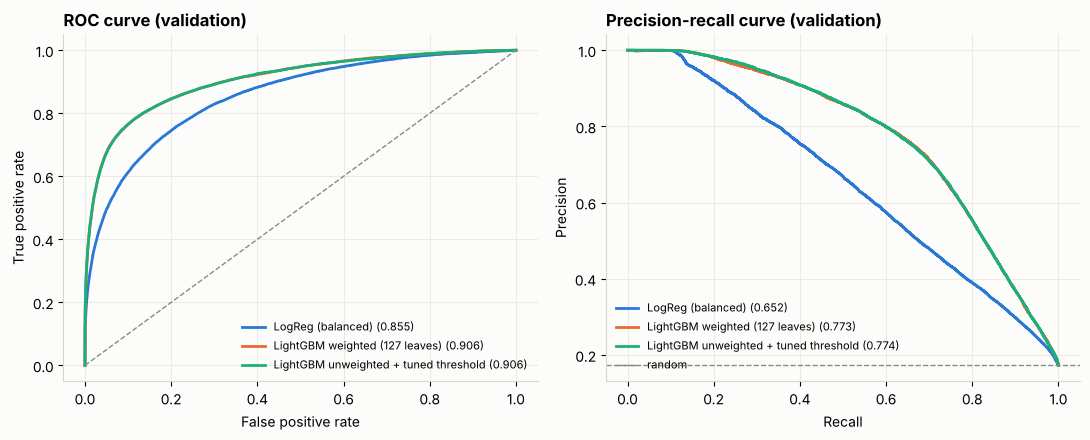

In [10]:
# ROC and precision-recall curves on validation for all compared models
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.5))
colors = [BLUE, ORANGE, AQUA]
for (m, c) in zip(cmp.index, colors):
    fpr, tpr, _ = roc_curve(y["validation"], val_scores[m]); a1.plot(fpr, tpr, color=c, lw=2, label=f"{m} ({cmp.loc[m, 'roc_auc']:.3f})")
    pr, rc, _ = precision_recall_curve(y["validation"], val_scores[m]); a2.plot(rc, pr, color=c, lw=2, label=f"{m} ({cmp.loc[m, 'pr_auc']:.3f})")
a1.plot([0, 1], [0, 1], color=GREY, ls="--", lw=1); a1.set_xlabel("False positive rate"); a1.set_ylabel("True positive rate"); a1.set_title("ROC curve (validation)")
a2.axhline(y["validation"].mean(), color=GREY, ls="--", lw=1, label="random"); a2.set_xlabel("Recall"); a2.set_ylabel("Precision"); a2.set_title("Precision-recall curve (validation)")
for a in (a1, a2): a.legend(fontsize=8, frameon=False, loc="lower left" if a is a2 else "lower right")
fig.tight_layout(); fig.savefig(FIG_DIR / "20_roc_pr_validation.png", dpi=130); plt.show()

## 8. Choosing the threshold (validation only)
The model outputs a probability; the **threshold** turns it into a yes/no flag.
* **Lower threshold** → flag more applications → catch more refusals (**recall ↑**) but more false alarms (**precision ↓**).
* **Higher threshold** → fewer, more certain flags → precision ↑, recall ↓.

**Business view:** a flag sends the application to *faster pre-screening / review*, it does **not** auto-reject anyone. A false alarm costs a little extra review time; a missed refusal wastes a full underwriting cycle. So we take the threshold that maximises **F1** (balance of both) on validation, and show the alternatives below so a credit manager can move it.

,threshold,precision,recall,f1,share_flagged,chosen
0,0.200,0.624,0.761,0.685,0.211,
1,0.300,0.698,0.709,0.703,0.176,
2,0.339,0.720,0.691,0.706,0.166,<- chosen
3,0.400,0.750,0.662,0.703,0.152,
4,0.500,0.790,0.612,0.690,0.134,
5,0.600,0.825,0.559,0.667,0.117,
6,0.700,0.862,0.495,0.629,0.099,


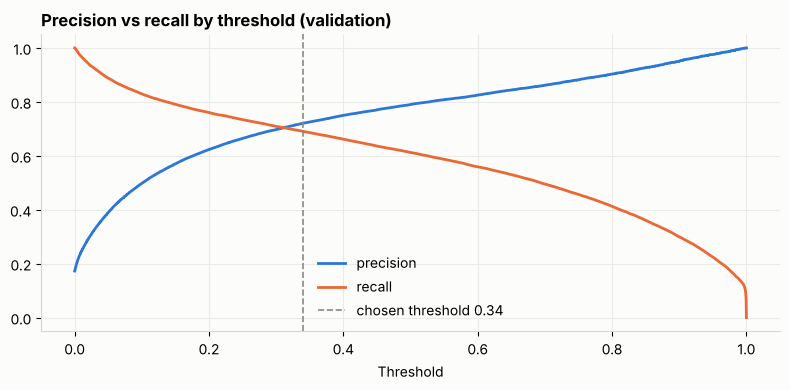

In [11]:
p_val = val_scores[FINAL_NAME]
rows = []
for t in sorted(set([0.2, 0.3, 0.4, 0.5, 0.6, 0.7, round(THRESHOLD, 3)])):
    r_ = evaluate(y["validation"], p_val, t, FINAL_NAME, "validation")
    rows.append({"threshold": t, "precision": r_["precision"], "recall": r_["recall"], "f1": r_["f1"],
                 "share_flagged": r_["predicted_refusal_rate"], "chosen": "<- chosen" if abs(t - THRESHOLD) < 1e-9 or t == round(THRESHOLD, 3) else ""})
display(pd.DataFrame(rows).round(3))

prec, rec, thr_ = precision_recall_curve(y["validation"], p_val)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thr_, prec[:-1], color=BLUE, lw=2, label="precision")
ax.plot(thr_, rec[:-1], color=ORANGE, lw=2, label="recall")
ax.axvline(THRESHOLD, color=GREY, ls="--", lw=1.2, label=f"chosen threshold {THRESHOLD:.2f}")
ax.set_xlabel("Threshold"); ax.set_title("Precision vs recall by threshold (validation)"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "21_threshold.png", dpi=130); plt.show()

## 9. Final evaluation — test set (once), then OOT (once)
Nothing below changes the model, the threshold or the risk bands.

,roc_auc,pr_auc,gini,ks,precision,recall,f1,accuracy,actual_refusal_rate,predicted_refusal_rate
split,,,,,,,,,,
train,0.9989,0.9950,0.9978,0.9682,0.9446,0.9759,0.9600,0.9859,0.1728,0.1785
validation,0.9058,0.7743,0.8116,0.6673,0.7206,0.6913,0.7056,0.9003,0.1728,0.1658
test,0.9041,0.7723,0.8082,0.6633,0.7159,0.6880,0.7017,0.8989,0.1728,0.1661
oot,0.8463,0.8065,0.6927,0.5158,0.8063,0.5633,0.6633,0.7869,0.3726,0.2603


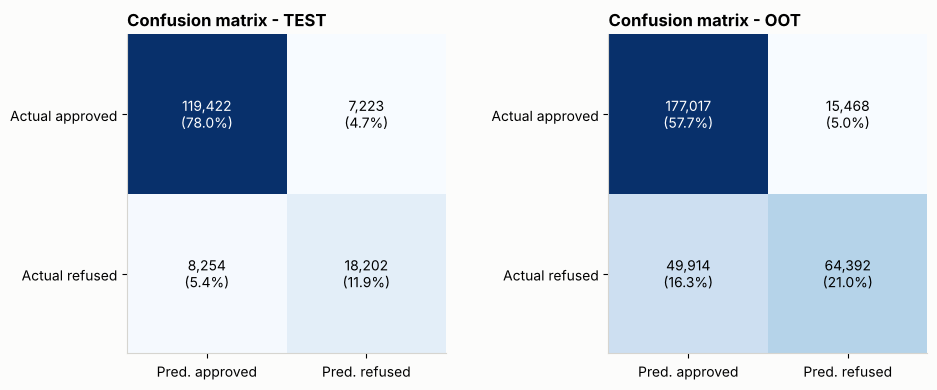

In [12]:
scores = {s: final_pipe.predict_proba(X[s])[:, 1] for s in ["train", "validation", "test", "oot"]}
final_rows = [evaluate(y[s], scores[s], THRESHOLD, FINAL_NAME, s) for s in ["train", "validation", "test", "oot"]]
final_df = pd.DataFrame(final_rows).set_index("split")
display(final_df[["roc_auc", "pr_auc", "gini", "ks", "precision", "recall", "f1", "accuracy",
                  "actual_refusal_rate", "predicted_refusal_rate"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for a, s in zip(axes, ["test", "oot"]):
    cm = confusion_matrix(y[s], (scores[s] >= THRESHOLD).astype(int))
    a.imshow(cm, cmap="Blues"); a.grid(False)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm.sum():.1%})", ha="center", va="center",
                   color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=10)
    a.set_xticks([0, 1], ["Pred. approved", "Pred. refused"]); a.set_yticks([0, 1], ["Actual approved", "Actual refused"])
    a.set_title(f"Confusion matrix - {s.upper()}")
fig.tight_layout(); fig.savefig(FIG_DIR / "22_confusion_test_oot.png", dpi=130); plt.show()

### Why is OOT different from test? (drift analysis)
Three checks:
1. **Base-rate shift** — the share of refusals in OOT vs development.
2. **PSI (Population Stability Index)** of the model score — how much the distribution of scores moved. Rule of thumb: < 0.10 stable, 0.10–0.25 moderate shift, > 0.25 major shift.
3. **Calibration** — predicted vs actual refusal rate.

Refusal rate  development: 17.3%  |  test: 17.3%  |  OOT: 37.3%
Mean predicted probability  test: 16.2%  |  OOT: 25.1%
Score PSI  validation -> test: 0.000  |  validation -> OOT: 0.217


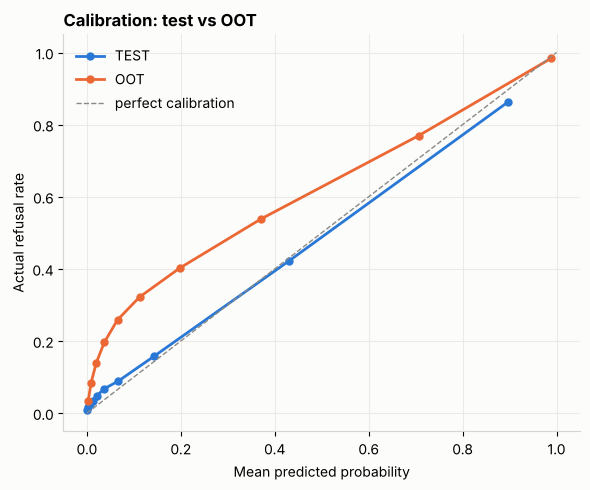

In [13]:
def psi(expected, actual, bins=10):
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

psi_test, psi_oot = psi(scores["validation"], scores["test"]), psi(scores["validation"], scores["oot"])
print(f"Refusal rate  development: {y['train'].mean():.1%}  |  test: {y['test'].mean():.1%}  |  OOT: {y['oot'].mean():.1%}")
print(f"Mean predicted probability  test: {scores['test'].mean():.1%}  |  OOT: {scores['oot'].mean():.1%}")
print(f"Score PSI  validation -> test: {psi_test:.3f}  |  validation -> OOT: {psi_oot:.3f}")

fig, ax = plt.subplots(figsize=(6, 5))
for s, c in [("test", BLUE), ("oot", ORANGE)]:
    frac_pos, mean_pred = calibration_curve(y[s], scores[s], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", ms=5, lw=2, color=c, label=s.upper())
ax.plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="perfect calibration")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Actual refusal rate"); ax.set_title("Calibration: test vs OOT")
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG_DIR / "23_calibration.png", dpi=130); plt.show()

In [14]:
# Decile (lift) table on TEST and OOT: rank applications by score, cut into 10 equal groups
def lift_table(y_true, p):
    d = pd.DataFrame({"y": y_true, "p": p})
    d["decile"] = pd.qcut(d["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
    t = d.groupby("decile", observed=True).agg(applications=("y", "size"), refusals=("y", "sum"),
                                                min_score=("p", "min"), max_score=("p", "max"))
    t["refusal_rate"] = t["refusals"] / t["applications"]
    t["lift"] = t["refusal_rate"] / d["y"].mean()
    t["cum_share_of_refusals"] = t["refusals"].cumsum() / t["refusals"].sum()
    return t.round(3)
print("TEST - decile 1 = highest scores"); display(lift_table(y["test"], scores["test"]))
print("OOT"); display(lift_table(y["oot"], scores["oot"]))

TEST - decile 1 = highest scores


,applications,refusals,min_score,max_score,refusal_rate,lift,cum_share_of_refusals
decile,,,,,,,
1,15311,13195,0.694,1.000,0.862,4.987,0.499
2,15310,6471,0.224,0.694,0.423,2.446,0.743
3,15310,2408,0.091,0.224,0.157,0.910,0.834
4,15310,1358,0.048,0.091,0.089,0.513,0.886
5,15310,1036,0.028,0.048,0.068,0.392,0.925
6,15310,745,0.016,0.028,0.049,0.282,0.953
7,15310,503,0.009,0.016,0.033,0.190,0.972
8,15310,368,0.004,0.009,0.024,0.139,0.986
9,15310,253,0.002,0.004,0.017,0.096,0.996


OOT


,applications,refusals,min_score,max_score,refusal_rate,lift,cum_share_of_refusals
decile,,,,,,,
1,30680,30179,0.908,1.000,0.984,2.640,0.264
2,30679,23615,0.508,0.908,0.770,2.066,0.471
3,30679,16509,0.263,0.508,0.538,1.444,0.615
4,30679,12335,0.146,0.263,0.402,1.079,0.723
5,30679,9877,0.085,0.146,0.322,0.864,0.809
6,30679,7929,0.049,0.085,0.258,0.694,0.879
7,30679,6021,0.027,0.049,0.196,0.527,0.931
8,30679,4254,0.013,0.027,0.139,0.372,0.969
9,30679,2585,0.005,0.013,0.084,0.226,0.991



### Interpretation: test vs OOT
* **Test ≈ validation** (ROC-AUC ≈ 0.904 vs 0.906, F1 ≈ 0.70 on both) → the model generalises to unseen applications from the same period; the threshold chosen on validation transfers cleanly.
* **Train is much higher (ROC-AUC ≈ 0.999)** — expected for boosted trees that have seen these exact rows. What matters is that validation and test agree; early stopping on validation kept adding trees only while validation PR-AUC improved.
* **OOT ranking drops moderately** (ROC-AUC ≈ 0.85 vs 0.90, KS ≈ 0.52 vs 0.66): the model still separates refusals from approvals well on newer data, but less sharply.
* **PR-AUC is *higher* on OOT (≈ 0.81)** only because refusals are more common there (37% vs 17%) — PR-AUC's baseline is the refusal rate, so it must be compared with care.
* **Recall falls (≈ 0.69 → 0.56) while precision rises (≈ 0.72 → 0.81)**: the model under-predicts refusals on OOT (mean predicted probability ≈ 25% vs actual 37%; calibration curve sits above the diagonal). It learned the older 17% refusal world.
* **Score PSI ≈ 0.22** (validation → OOT) = moderate population shift.

**Why the drop:** the refusal rate doubled in the most recent year (product mix moved towards cash loans, more incomplete `XNA`-portfolio applications, more re-applications), so the base rate the model learned is out of date.
**What a lender would do:** retrain on more recent data or recalibrate probabilities on the latest months, lower the threshold for the current period, and monitor PSI and the actual refusal rate by risk band monthly.


## 10. Risk bands (Low / Medium / High)
Cut-offs are set on **validation** and then applied unchanged to test and OOT:
* **High** — probability ≥ the chosen threshold: the model flags these as likely refusals → route to fast pre-screening, or guide the customer to a smaller amount / different product.
* **Low** — probability below the cut-off where the validation refusal rate of everything below it stays ≤ 5% → candidates for fast-track processing.
* **Medium** — in between → standard underwriting.

In [15]:
order = np.argsort(p_val)
cum_rate = np.cumsum(y["validation"][order]) / np.arange(1, len(order) + 1)
ok = np.where(cum_rate <= 0.05)[0]
LOW_CUT = float(p_val[order][ok.max()]) if len(ok) else float(np.quantile(p_val, 0.2))
LOW_CUT = min(LOW_CUT, THRESHOLD * 0.5)
BANDS = {"Low": f"probability < {LOW_CUT:.3f}", "Medium": f"{LOW_CUT:.3f} <= probability < {THRESHOLD:.3f}", "High": f"probability >= {THRESHOLD:.3f}"}

def band(p):
    return np.select([p < LOW_CUT, p < THRESHOLD], ["Low", "Medium"], "High")

print("Band definitions:", json.dumps(BANDS, indent=2))
band_rows = []
for s in ["validation", "test", "oot"]:
    b = pd.DataFrame({"band": band(scores[s]), "y": y[s]})
    t = b.groupby("band")["y"].agg(applications="size", refusal_rate="mean").reindex(["Low", "Medium", "High"])
    t["share_of_applications"] = t["applications"] / len(b)
    t["share_of_all_refusals"] = b.groupby("band")["y"].sum().reindex(t.index) / b["y"].sum()
    t.insert(0, "split", s); band_rows.append(t.reset_index())
band_df = pd.concat(band_rows, ignore_index=True)
display(band_df.round(3))

Band definitions: {
  "Low": "probability < 0.170",
  "Medium": "0.170 <= probability < 0.339",
  "High": "probability >= 0.339"
}


,band,split,applications,refusal_rate,share_of_applications,share_of_all_refusals
0,Low,validation,118414,0.050,0.773,0.222
1,Medium,validation,9306,0.247,0.061,0.087
2,High,validation,25380,0.721,0.166,0.691
3,Low,test,118463,0.050,0.774,0.226
4,Medium,test,9213,0.248,0.060,0.086
5,High,test,25425,0.716,0.166,0.688
6,Low,oot,192317,0.180,0.627,0.303
7,Medium,oot,34614,0.440,0.113,0.133
8,High,oot,79860,0.806,0.260,0.563


## 11. Feature importance (global, final model)
LightGBM **gain** importance = how much each feature improved the model's fit, summed over all trees, shown as a share of the total.

**Limitations:** it measures *predictive usefulness*, not cause and effect (a feature can be important because it is correlated with the real driver); correlated features share credit between them; and it does not show the direction of the effect (use the EDA charts for that).

,feature,importance,rank,group
0,DAYS_SINCE_PRIOR_APP,0.1838,1,History
1,NAME_PORTFOLIO,0.0544,2,Product
2,PRODUCT_COMBINATION,0.0523,3,Product
3,EXT_SOURCE_3,0.0474,4,Financial
4,ORGANIZATION_TYPE,0.0400,5,Financial
5,NAME_PRODUCT_TYPE,0.0368,6,Product
6,NAME_GOODS_CATEGORY,0.0363,7,Product
7,AGE_AT_DECISION,0.0350,8,Demographic
8,EXT_SOURCE_2,0.0325,9,Financial
9,EXT_SOURCE_MEAN,0.0304,10,Financial


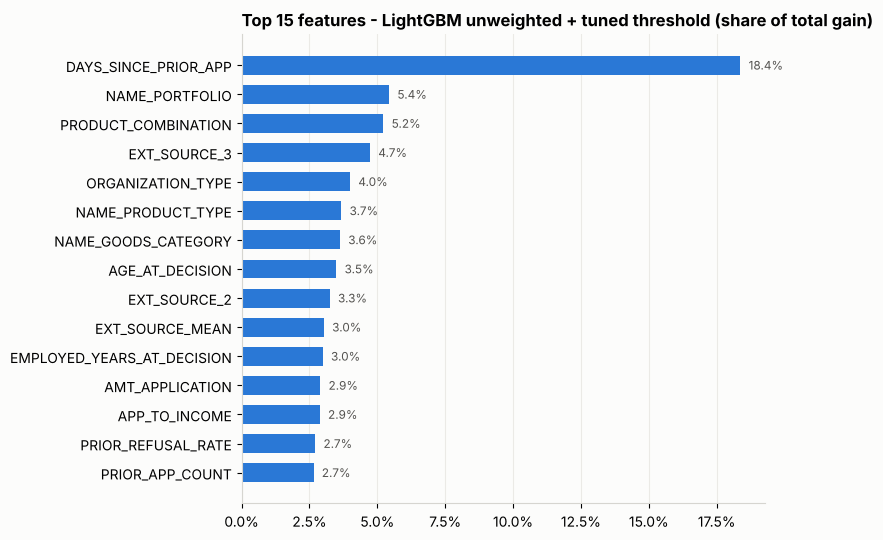

Importance by feature group:
 group
Product        0.333
Financial      0.278
History        0.260
Demographic    0.080
Channel        0.049


In [16]:
model_step = final_pipe.named_steps["model"]
if hasattr(model_step, "booster_"):
    names = NUM + CAT                                    # ColumnTransformer output order = numeric, then categorical
    imp = pd.Series(model_step.booster_.feature_importance("gain"), index=names)
else:                                                   # Logistic Regression fallback: |coefficient| summed per original feature
    out_names = final_pipe.named_steps["pre"].get_feature_names_out()
    coefs = pd.Series(np.abs(model_step.coef_[0]), index=out_names)
    imp = pd.Series({f: coefs[[n for n in out_names if f in n]].sum() for f in FEATURES})
fi = (imp / imp.sum()).sort_values(ascending=False).rename("importance").to_frame()
fi["rank"] = range(1, len(fi) + 1)
fi = fi.join(groups.set_index("feature")).reset_index().rename(columns={"index": "feature"})
display(fi.head(20).round(4))

top = fi.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top["feature"], top["importance"], color=BLUE, height=0.65)
for yy, v in enumerate(top["importance"]): ax.text(v + 0.003, yy, f"{v:.1%}", va="center", fontsize=8.5, color=INK2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.grid(axis="y", visible=False)
ax.set_title(f"Top 15 features - {FINAL_NAME} (share of total gain)")
fig.tight_layout(); fig.savefig(FIG_DIR / "24_feature_importance.png", dpi=130); plt.show()
print("Importance by feature group:\n", fi.groupby("group")["importance"].sum().sort_values(ascending=False).round(3).to_string())

## 12. Save model and dashboard files
* `final_model.joblib` — fitted pipeline + threshold + band cut-offs + feature list (everything needed to score a new application)
* `predictions.csv` — one row per application: id, split, actual, probability, prediction, risk band
* `model_metrics.csv` — KPIs by model and by split (long format, easy to use in Power BI)
* `feature_importance.csv` — feature, importance, rank, group

In [17]:
artefact = {"pipeline": final_pipe, "model_name": FINAL_NAME, "threshold": THRESHOLD, "low_cut": LOW_CUT,
            "bands": BANDS, "features": FEATURES, "numeric_features": NUM, "categorical_features": CAT,
            "versions": {"lightgbm": lgb.__version__, "sklearn": sklearn.__version__, "pandas": pd.__version__}}
joblib.dump(artefact, MODEL_DIR / "final_model.joblib", compress=3)

pred = pd.concat([pd.DataFrame({"SK_ID_PREV": df.loc[split[s], "SK_ID_PREV"].values, "SPLIT": s, "ACTUAL_REFUSED": y[s],
                                "REFUSAL_PROBABILITY": np.round(scores[s], 4)}) for s in ["train", "validation", "test", "oot"]],
                 ignore_index=True)
pred["PREDICTED_REFUSED"] = (pred["REFUSAL_PROBABILITY"] >= THRESHOLD).astype(int)
pred["RISK_BAND"] = band(pred["REFUSAL_PROBABILITY"].values)
assert len(pred) == len(df) and pred["SK_ID_PREV"].is_unique
pred.to_csv(OUT_DIR / "predictions.csv", index=False)

metrics_rows = [r for r in results] + [r for r in final_rows if r["split"] != "validation"]
metrics = pd.DataFrame(metrics_rows)
metrics["is_final_model"] = (metrics["model"] == FINAL_NAME).astype(int)
metrics.drop(columns=["best_iteration"], errors="ignore").round(4).to_csv(OUT_DIR / "model_metrics.csv", index=False)
fi.round(6).to_csv(OUT_DIR / "feature_importance.csv", index=False)
band_df.round(4).to_csv(OUT_DIR / "risk_band_summary.csv", index=False)
abl_df.round(4).to_csv(OUT_DIR / "ablation_results.csv")

# reload check: the saved model must reproduce the scores exactly
reloaded = joblib.load(MODEL_DIR / "final_model.joblib")
assert np.allclose(reloaded["pipeline"].predict_proba(X["test"].head(1000))[:, 1], scores["test"][:1000])
for f in ["predictions.csv", "model_metrics.csv", "feature_importance.csv", "risk_band_summary.csv", "ablation_results.csv"]:
    print(f"{f:26s} {(OUT_DIR / f).stat().st_size / 1e6:6.1f} MB")
print(f"{'final_model.joblib':26s} {(MODEL_DIR / 'final_model.joblib').stat().st_size / 1e6:6.1f} MB  (reload check passed)")

predictions.csv              38.8 MB
model_metrics.csv             0.0 MB
feature_importance.csv        0.0 MB
risk_band_summary.csv         0.0 MB
ablation_results.csv          0.0 MB
final_model.joblib           19.0 MB  (reload check passed)


## 13. Scoring a new application (how the model would be used)

In [18]:
art = joblib.load(MODEL_DIR / "final_model.joblib")
new_app = X["oot"].head(3)                       # pretend these just arrived
p_new = art["pipeline"].predict_proba(new_app[art["features"]])[:, 1]
pd.DataFrame({"refusal_probability": p_new.round(3),
              "risk_band": np.select([p_new < art["low_cut"], p_new < art["threshold"]], ["Low", "Medium"], "High")})

,refusal_probability,risk_band
0,0.029,Low
1,0.146,Low
2,0.001,Low



## Summary — what to say about this notebook
* **Baseline:** Logistic Regression (class-weighted) → validation ROC-AUC 0.855, PR-AUC 0.652.
* **Stronger:** LightGBM → validation ROC-AUC 0.906, PR-AUC 0.774 (+0.12 PR-AUC over the baseline). Tree size chosen on validation (127 leaves).
* **Imbalance:** compared class weighting (`scale_pos_weight` 4.8) vs no weighting + threshold tuning — equal ranking quality; the **unweighted** model was chosen because its probabilities are better calibrated (Brier 0.074 vs 0.083), which matters for risk bands and the dashboard.
* **Threshold** ≈ 0.34, chosen on validation by maximum F1 (precision ≈ 0.72, recall ≈ 0.69). A table of alternatives is shown for the business.
* **Leakage/reliance check:** removing `NAME_PORTFOLIO` changes nothing (its signal is shared with other product columns); removing the time since the previous application costs ~0.04 PR-AUC; removing all history features costs ~0.07 — real, legitimate signal, not one leaked column.
* **Test** matches validation → no overfitting to the validation set. **OOT** shows a moderate drop in ranking and a recall drop driven by the doubled refusal rate (drift, PSI ≈ 0.22).
* **Risk bands:** Low ≈ 77% of applications with ~5% refusals (fast-track), High ≈ 17% with ~72% refusals (pre-screen), on test.
* **Top drivers:** time since previous application, product portfolio/combination, external scores, organisation type, age, requested amount vs income.
* Probabilities are reasonably calibrated on test, **not** on OOT (under-predicts) — stated as a limitation.
